In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Configure plotting style
sns.set_theme(style='whitegrid')
print('Required libraries imported successfully!')

Required libraries imported successfully!


In [2]:
df=pd.read_csv('/content/Employee.csv')
df.shape

(148, 6)

In [3]:
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


** Data Exploration and Renaming**


In [4]:
# 1. Rename columns to standard lowercase
df.columns = df.columns.str.strip().str.lower()
print("Renamed columns:", list(df.columns))

Renamed columns: ['company', 'age', 'salary', 'place', 'country', 'gender']


In [5]:
# 2. Explore unique values and their lengths
for col in df.columns:
    unique_vals = df[col].unique()
    print(f"Column: {col}")
    print(f"  Number of unique values: {len(unique_vals)}")
    print(f"  Unique values: {unique_vals}\n")

Column: company
  Number of unique values: 7
  Unique values: ['TCS' 'Infosys' 'CTS' nan 'Tata Consultancy Services' 'Congnizant'
 'Infosys Pvt Lmt']

Column: age
  Number of unique values: 30
  Unique values: [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.]

Column: salary
  Number of unique values: 41
  Unique values: [  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 9000. 1089. 1234. 3030.
 3045. 3184. 4824. 5835. 7084. 8943. 8345. 9284. 9876. 2034. 7654. 2934.
 4034. 5034. 8202. 9024. 4345. 6544. 6543. 3234. 4324. 5435. 5555. 8787.
 3454. 5654. 5009. 5098. 3033.]

Column: place
  Number of unique values: 12
  Unique values: ['Chennai' 'Mumbai' 'Calcutta' 'Delhi' 'Podicherry' 'Cochin' nan 'Noida'
 'Hyderabad' 'Bhopal' 'Nagpur' 'Pune']

Column: country
  Number of unique values: 1
  Unique values: ['India']

Column: gender
  Number of unique values: 2
  Unique values: [0 1]



In [6]:
# 3. Statistical Analysis
print("--- Numerical Columns Summary ---")
display(df.describe(include='all'))

--- Numerical Columns Summary ---


,company,age,salary,place,country,gender
count,140,130.000000,124.000000,134,148,148.000000
unique,6,NaN,NaN,11,1,NaN
top,TCS,NaN,NaN,Mumbai,India,NaN
freq,53,NaN,NaN,37,148,NaN
mean,NaN,30.484615,5312.467742,NaN,NaN,0.222973
std,NaN,11.096640,2573.764683,NaN,NaN,0.417654
min,NaN,0.000000,1089.000000,NaN,NaN,0.000000
25%,NaN,22.000000,3030.000000,NaN,NaN,0.000000
50%,NaN,32.500000,5000.000000,NaN,NaN,0.000000
75%,NaN,37.750000,8000.000000,NaN,NaN,0.000000


**Data Cleaning**


In [7]:
# 1. Treat inappropriate values
# Replace age 0 with NaN
df['age'] = df['age'].replace(0, np.nan)

# Standardize inconsistent formatting in 'company'
company_mapping = {
    'Tata Consultancy Services': 'TCS',
    'Infosys Pvt Lmt': 'Infosys',
    'Congnizant': 'CTS'
}
df['company'] = df['company'].replace(company_mapping)

print("Unique company names after standardization:", df['company'].unique())
print("Unique age values after treating 0:", df['age'].unique())

Unique company names after standardization: ['TCS' 'Infosys' 'CTS' nan]
Unique age values after treating 0: [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17. 54.]


In [8]:
# 2. Remove all duplicate rows
initial_shape = df.shape
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {initial_shape[0] - df.shape[0]} duplicate rows. New dataset shape: {df.shape}")

Removed 4 duplicate rows. New dataset shape: (144, 6)


In [9]:
# 3. Treat null values
print("Null values count before imputation:")
print(df.isnull().sum())

# Numerical columns: impute with median (since salary & age may contain outliers)
df['age'] = df['age'].fillna(df['age'].median())
df['salary'] = df['salary'].fillna(df['salary'].median())

# Categorical columns: impute with mode
df['company'] = df['company'].fillna(df['company'].mode()[0])
df['place'] = df['place'].fillna(df['place'].mode()[0])

print("\nNull values count after imputation:")
print(df.isnull().sum())

Null values count before imputation:
company     8
age        23
salary     23
place      14
country     0
gender      0
dtype: int64

Null values count after imputation:
company    0
age        0
salary     0
place      0
country    0
gender     0
dtype: int64


In [10]:
# 4. Find Outliers using the Interquartile Range (IQR) method
def find_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return outliers, lower_bound, upper_bound

for num_col in ['age', 'salary']:
    outliers, lb, ub = find_outliers(df[num_col])
    print(f"Column: {num_col}")
    print(f"  Bounds: [{lb:.2f}, {ub:.2f}]")
    print(f"  Number of outliers found: {len(outliers)}")
    if len(outliers) > 0:
        print(f"  Outliers: {outliers.values}\n")
    else:
        print("  No outliers found.\n")

Column: age
  Bounds: [5.38, 54.38]
  Number of outliers found: 0
  No outliers found.

Column: salary
  Bounds: [-3013.50, 13142.50]
  Number of outliers found: 0
  No outliers found.



**Data analysis**

In [11]:
# 1. Filter the data (age > 40 and salary < 5000)
filtered_df = df[(df['age'] > 40) & (df['salary'] < 5000)]
print(f"Number of employees with age > 40 and salary < 5000: {len(filtered_df)}")
display(filtered_df)

Number of employees with age > 40 and salary < 5000: 15


,company,age,salary,place,country,gender
21,Infosys,50.0,3184.0,Delhi,India,0
32,Infosys,45.0,4034.0,Calcutta,India,0
39,Infosys,41.0,3000.0,Mumbai,India,0
50,Infosys,41.0,3000.0,Chennai,India,0
57,Infosys,51.0,3184.0,Hyderabad,India,0
68,Infosys,43.0,4034.0,Mumbai,India,0
75,Infosys,44.0,3000.0,Cochin,India,0
85,Infosys,41.0,3000.0,Delhi,India,0
92,Infosys,54.0,3184.0,Mumbai,India,0
103,Infosys,44.0,4034.0,Delhi,India,0


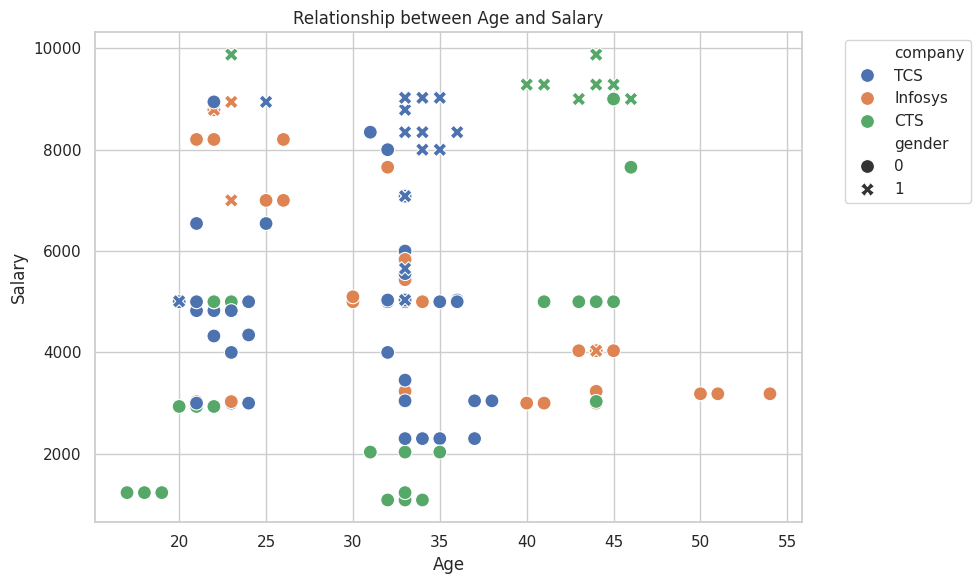

In [12]:
# 2. Plot the relationship between age and salary
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='salary', hue='company', style='gender', s=100)
plt.title('Relationship between Age and Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

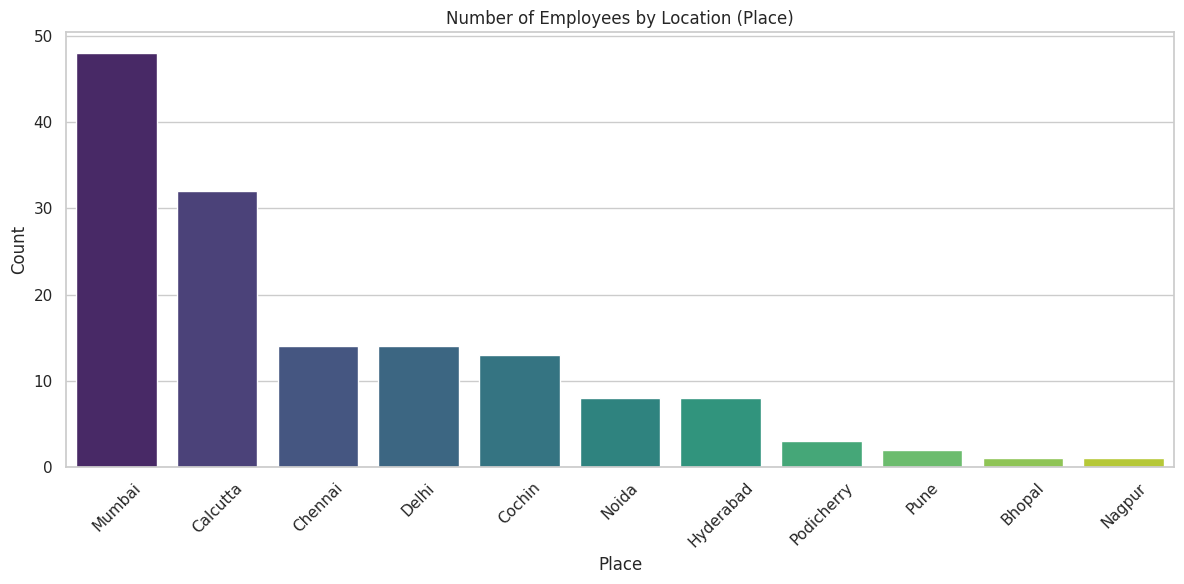

In [13]:
# 3. Count people from each place and represent it visually
place_counts = df['place'].value_counts().reset_index()
place_counts.columns = ['place', 'count']

plt.figure(figsize=(12, 6))
sns.barplot(data=place_counts, x='place', y='count', palette='viridis', hue='place', legend=False)
plt.title('Number of Employees by Location (Place)')
plt.xlabel('Place')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Data Encoding**


In [15]:
# Identify categorical columns to encode
categorical_cols = ['company', 'place', 'country']

# Create a copy of the dataframe for encoding
df_encoded = df.copy()

# Apply One-Hot Encoding using pandas get_dummies
df_encoded = pd.get_dummies(df_encoded, columns=categorical_cols, drop_first=True, dtype=int)

print("Encoded DataFrame Shape:", df_encoded.shape)
print("\nEncoded DataFrame Columns:")
print(df_encoded.columns.tolist())

# Preview the prepared dataset
display(df_encoded.head())

Encoded DataFrame Shape: (144, 15)

Encoded DataFrame Columns:
['age', 'salary', 'gender', 'company_Infosys', 'company_TCS', 'place_Calcutta', 'place_Chennai', 'place_Cochin', 'place_Delhi', 'place_Hyderabad', 'place_Mumbai', 'place_Nagpur', 'place_Noida', 'place_Podicherry', 'place_Pune']


,age,salary,gender,company_Infosys,company_TCS,place_Calcutta,place_Chennai,place_Cochin,place_Delhi,place_Hyderabad,place_Mumbai,place_Nagpur,place_Noida,place_Podicherry,place_Pune
0,20.0,5000.0,0,0,1,0,1,0,0,0,0,0,0,0,0
1,30.0,5000.0,0,1,0,0,0,0,0,0,1,0,0,0,0
2,35.0,2300.0,0,0,1,1,0,0,0,0,0,0,0,0,0
3,40.0,3000.0,0,1,0,0,0,0,1,0,0,0,0,0,0
4,23.0,4000.0,0,0,1,0,0,0,0,0,1,0,0,0,0


 **Feature Scaling**


In [19]:
# Identify continuous numerical columns to scale
num_cols = ['age', 'salary']

# 1. StandardScaler
scaler_standard = StandardScaler()
df_standard_scaled = df_encoded.copy()
df_standard_scaled[num_cols] = scaler_standard.fit_transform(df_encoded[num_cols])

print("--- Features scaled using StandardScaler (First 5 Rows) ---")
display(df_standard_scaled[num_cols].head())

--- Features scaled using StandardScaler (First 5 Rows) ---


,age,salary
0,-1.484676,-0.100827
1,-0.267174,-0.100827
2,0.341577,-1.243735
3,0.950328,-0.947426
4,-1.119426,-0.524127


In [18]:
# 2. MinMaxScaler
scaler_minmax = MinMaxScaler()
df_minmax_scaled = df_encoded.copy()
df_minmax_scaled[num_cols] = scaler_minmax.fit_transform(df_encoded[num_cols])

print("--- Features scaled using MinMaxScaler (First 5 Rows) ---")
display(df_minmax_scaled[num_cols].head())

--- Features scaled using MinMaxScaler (First 5 Rows) ---


,age,salary
0,0.081081,0.445089
1,0.351351,0.445089
2,0.486486,0.137817
3,0.621622,0.217480
4,0.162162,0.331285
